# Many attachments, one changing force

How can attachment and detachment produce a changing population-level force?

Fall 2024.


Predict: with attachment 3/s and detachment 1/s, where should the attached fraction settle? What changes if both rates double? The cells below use original synthetic parameters.

In [1]:
from demo import run, advance, force_pn
from IPython.display import SVG, display
result = run()
result

{'model': 'two-state occupancy; fixed per-head force is a separate illustrative readout',
 'equilibrium_for_f3_g1': 0.75,
 'relaxation_time_s': 0.25,
 'force_for_1000_heads_2pN_each_at_equilibrium_pN': 1500,
 'protocol_fraction_at_0_1_2_3_seconds': [0.5,
  0.5,
  0.7454210902778164,
  0.27422509412881035],
 'checks': {'bounds': True,
  'zero_rates_preserve_state': True,
  'equilibrium_preserved': True,
  'rate_time_scaling': True,
  'semigroup': True,
  'pure_detachment': True,
  'invalid_cases_rejected': 5},
 'limitations': ['no strain distribution',
  'no sliding or shortening speed',
  'no ATP consumption model',
  'no calcium activation dynamics',
  'not a ventricular force prediction']}

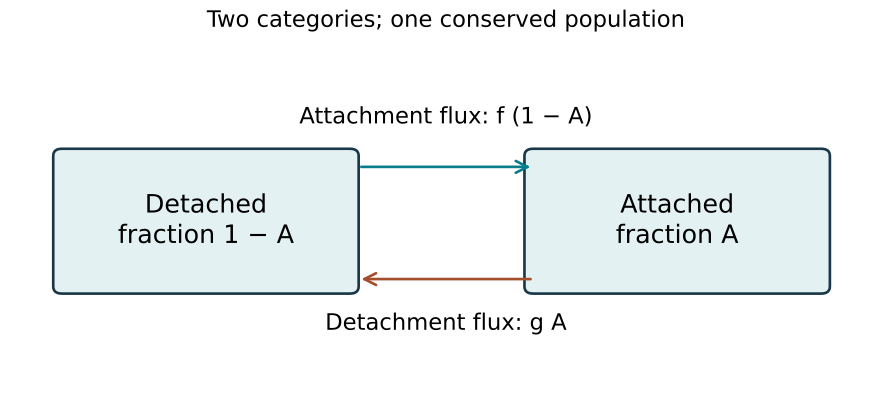

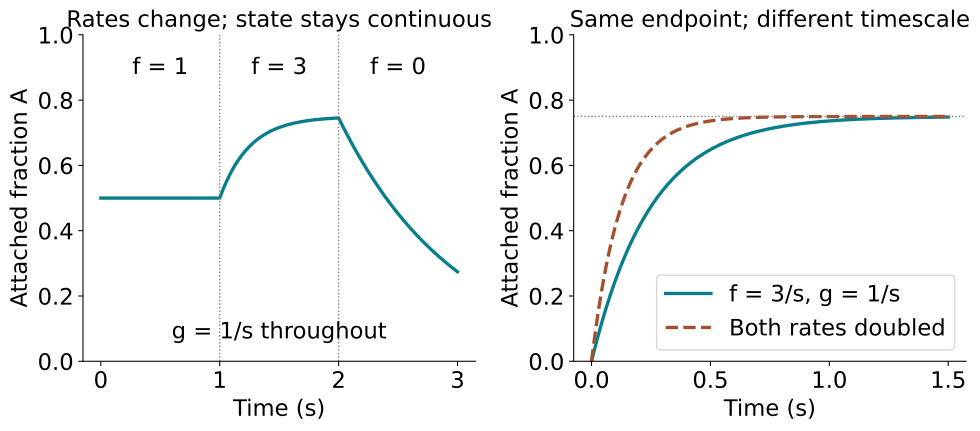

In [2]:
display(SVG(filename='state-balance.svg'))
display(SVG(filename='occupancy-traces.svg'))

Interpret: locate the two rate switches. Explain why the fraction remains continuous. Separate the occupancy model from the fixed-force assumption.

In [3]:
import numpy as np
times = np.array([0., 0.25, 0.5, 1.])
fractions = advance(0., times, 3., 1.)
list(zip(times, fractions, force_pn(fractions)))

[(np.float64(0.0), np.float64(0.0), np.float64(0.0)),
 (np.float64(0.25),
  np.float64(0.47409041912141825),
  np.float64(948.1808382428364)),
 (np.float64(0.5),
  np.float64(0.6484985375725405),
  np.float64(1296.997075145081)),
 (np.float64(1.0),
  np.float64(0.7362632708334493),
  np.float64(1472.5265416668988))]

Modify: before executing the next cell, predict the effect of doubling both rates while retaining the same initial fraction. Compare at identical times and at rescaled times.

In [4]:
faster = advance(0., times, 6., 2.)
print('Original:', fractions)
print('Both rates doubled:', faster)
print('Matches original at twice the time:', np.allclose(faster, advance(0., 2*times, 3., 1.)))

Original: [0.         0.47409042 0.64849854 0.73626327]
Both rates doubled: [0.         0.64849854 0.73626327 0.7497484 ]
Matches original at twice the time: True
